# Tourist Behaviour and Tourist Analysis
### A Python for Data Science Project

| | |
|---|---|
| **Student Name** | Gokul Prasad .M |
| **Register Number** | RA2431022020007 |
| **Programme** | B.Sc. Artificial Intelligence and Machine Learning |
| **College** | SRM Institute of Science and Technology, Ramapuram |
| **Company** | Inspire Softech Solutions |

---

# Tourist Behaviour and Tourist Analysis
### Subject: Python for Data Science

**Project Goal:** Analyze tourist demographics, travel patterns, spending, destinations, transportation, activities and satisfaction using Python.

**Tools:** Pandas, NumPy, Matplotlib, Seaborn, Plotly and Scikit-learn.

This notebook is arranged like a complete beginner-friendly data science project: data loading → cleaning → exploration → visualization → insights → machine learning.

In [1]:
# Install the libraries used in this project
# Run this cell in Google Colab
!pip -q install pandas numpy matplotlib seaborn plotly scikit-learn

## 1. Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.cluster import KMeans

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")


## 2. Load the tourist dataset

### In Google Colab
Upload the CSV file from the ZIP into Colab using the file panel. The code below first looks for the supplied project filename and then lets you upload it if necessary.

In [3]:
import os
import pandas as pd

file_name = "Tourist_Behavior_Travel_Analytics_Dataset.csv"

if not os.path.exists(file_name):
    from google.colab import files
    uploaded = files.upload()
    file_name = next(iter(uploaded))

df = pd.read_csv(file_name)
print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
df.head()

Dataset loaded successfully!
Rows: 1508
Columns: 13


,Tourist_ID,Age,Gender,Country,Travel_Frequency,Travel_Type,Destination,Trip_Duration,Accommodation_Type,Transportation,Activities,Total_Spending,Satisfaction_Rating
0,T10001,39,Male,India,Frequently,Family,Himachal Pradesh,6,Budget Hotel,Flight,Sightseeing,36453,3
1,T10002,32,Female,USA,Occasionally,Solo,Karnataka,8,Hostel,Flight,Cultural,52381,4
2,T10003,41,Female,Singapore,Frequently,Solo,Karnataka,6,Budget Hotel,Bus,Adventure,21440,4
3,T10004,51,Male,Singapore,Frequently,Family,Karnataka,5,Budget Hotel,Bus,Beach,8930,4
4,T10005,31,Male,India,Occasionally,Couple,Delhi,8,Budget Hotel,Car,Sightseeing,45296,4


## 3. Understand the dataset

In [4]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
df.info()

Dataset shape: (1508, 13)

Column names:
['Tourist_ID', 'Age', 'Gender', 'Country', 'Travel_Frequency', 'Travel_Type', 'Destination', 'Trip_Duration', 'Accommodation_Type', 'Transportation', 'Activities', 'Total_Spending', 'Satisfaction_Rating']

Data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1508 entries, 0 to 1507
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Tourist_ID           1508 non-null   object
 1   Age                  1508 non-null   int64 
 2   Gender               1502 non-null   object
 3   Country              1508 non-null   object
 4   Travel_Frequency     1508 non-null   object
 5   Travel_Type          1508 non-null   object
 6   Destination          1508 non-null   object
 7   Trip_Duration        1508 non-null   int64 
 8   Accommodation_Type   1508 non-null   object
 9   Transportation       1502 non-null   object
 10  Activities           1502 non-null   obje

In [5]:
# Basic numerical summary
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1508.0,34.799072,10.378763,18.0,27.0,35.0,41.25,70.0
Trip_Duration,1508.0,5.803714,2.128253,2.0,4.0,6.0,7.00,13.0
Total_Spending,1508.0,34824.647215,20604.065448,5000.0,19728.5,30855.5,45322.50,166285.0
Satisfaction_Rating,1508.0,3.588859,0.659318,2.0,3.0,4.0,4.00,5.0


In [6]:
# Check missing values and duplicate rows
print("Missing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
Tourist_ID             0
Age                    0
Gender                 6
Country                0
Travel_Frequency       0
Travel_Type            0
Destination            0
Trip_Duration          0
Accommodation_Type     0
Transportation         6
Activities             6
Total_Spending         0
Satisfaction_Rating    0
dtype: int64

Duplicate rows: 8


## 4. Data cleaning

The dataset contains a small number of missing values in Gender, Transportation and Activities. For categorical columns, the most frequent value (mode) is a simple and explainable choice for an internship project.

In [7]:
df = df.copy()

categorical_columns = ["Gender", "Transportation", "Activities"]
for column in categorical_columns:
    df[column] = df[column].fillna(df[column].mode()[0])

# Remove exact duplicate records if any
df = df.drop_duplicates().reset_index(drop=True)

print("Cleaning completed.")
print("Remaining missing values:", df.isnull().sum().sum())
print("Final shape:", df.shape)

Cleaning completed.
Remaining missing values: 0
Final shape: (1500, 13)


## 5. Tourist profile analysis

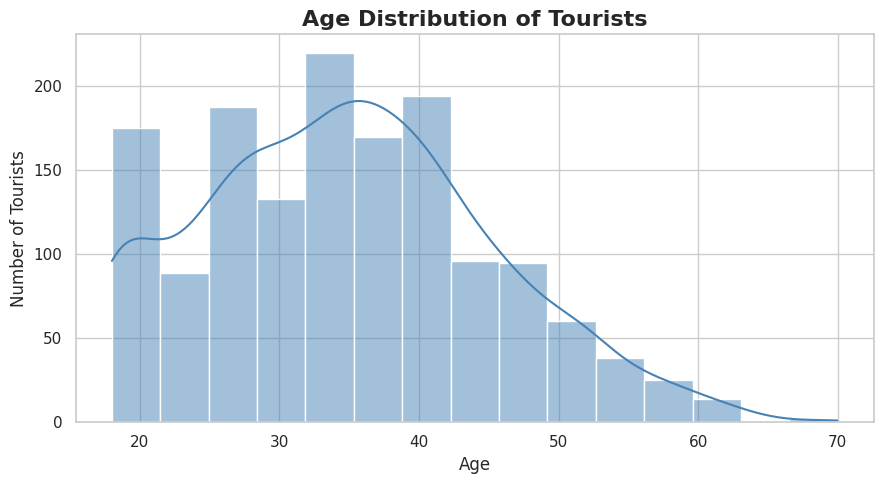

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=df, x="Age", bins=15, kde=True, color="steelblue", ax=ax)
ax.set_title("Age Distribution of Tourists", fontsize=16, fontweight="bold")
ax.set_xlabel("Age")
ax.set_ylabel("Number of Tourists")
plt.tight_layout()
plt.show()

In [9]:
gender_count = df["Gender"].value_counts().reset_index()
gender_count.columns = ["Gender", "Tourists"]

fig = px.pie(gender_count, names="Gender", values="Tourists", hole=0.45,
             title="Tourist Distribution by Gender")
fig.update_traces(textposition="inside", textinfo="percent+label")
fig.show()

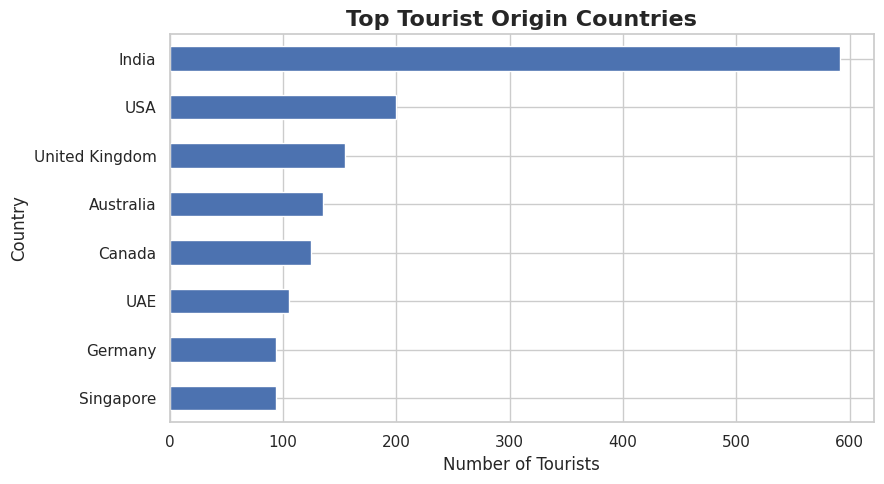

In [10]:
country_count = df["Country"].value_counts().head(10).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
country_count.plot(kind="barh", ax=ax)
ax.set_title("Top Tourist Origin Countries", fontsize=16, fontweight="bold")
ax.set_xlabel("Number of Tourists")
ax.set_ylabel("Country")
plt.tight_layout()
plt.show()

## 6. Travel behaviour analysis

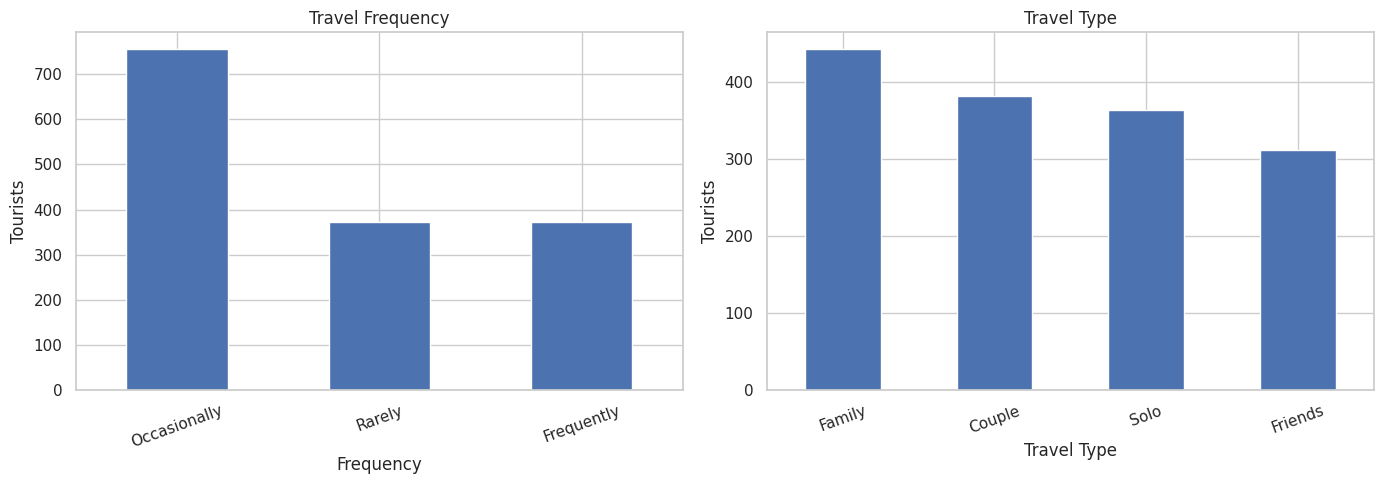

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df["Travel_Frequency"].value_counts().plot(kind="bar", ax=axes[0])
axes[0].set_title("Travel Frequency")
axes[0].set_xlabel("Frequency")
axes[0].set_ylabel("Tourists")
axes[0].tick_params(axis="x", rotation=20)

df["Travel_Type"].value_counts().plot(kind="bar", ax=axes[1])
axes[1].set_title("Travel Type")
axes[1].set_xlabel("Travel Type")
axes[1].set_ylabel("Tourists")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

In [12]:
transport_count = df["Transportation"].value_counts().reset_index()
transport_count.columns = ["Transportation", "Tourists"]
fig = px.bar(transport_count, x="Transportation", y="Tourists",
             title="Preferred Transportation Used by Tourists", text="Tourists")
fig.update_traces(textposition="outside")
fig.show()

In [13]:
activity_count = df["Activities"].value_counts().reset_index()
activity_count.columns = ["Activities", "Tourists"]
fig = px.bar(activity_count.sort_values("Tourists"), x="Tourists", y="Activities",
             orientation="h", title="Popular Tourist Activities", text="Tourists")
fig.update_traces(textposition="outside")
fig.show()

## 7. Destination analysis

In [14]:
destination_summary = (
    df.groupby("Destination")
      .agg(Tourists=("Tourist_ID", "count"),
           Average_Spending=("Total_Spending", "mean"),
           Average_Satisfaction=("Satisfaction_Rating", "mean"),
           Average_Trip_Days=("Trip_Duration", "mean"))
      .sort_values("Tourists", ascending=False)
)

destination_summary.round(2)

,Tourists,Average_Spending,Average_Satisfaction,Average_Trip_Days
Destination,,,,
Rajasthan,380,35235.54,3.56,5.87
Karnataka,216,35094.41,3.56,5.84
Himachal Pradesh,193,35494.52,3.62,5.99
Kerala,192,35651.16,3.64,5.78
Tamil Nadu,190,33114.91,3.62,5.66
Goa,169,34495.22,3.57,5.80
Delhi,160,33776.52,3.58,5.53


In [15]:
top_destinations = destination_summary.head(10).reset_index()
fig = px.bar(top_destinations, x="Tourists", y="Destination", orientation="h",
             title="Top Destinations by Tourist Count", text="Tourists")
fig.update_traces(textposition="outside")
fig.update_layout(yaxis=dict(categoryorder="total ascending"))
fig.show()

In [16]:
fig = px.scatter(destination_summary.reset_index(),
                 x="Average_Spending", y="Average_Satisfaction",
                 size="Tourists", color="Destination",
                 hover_data=["Average_Trip_Days"],
                 title="Destination: Spending vs Satisfaction")
fig.show()

## 8. Spending and trip-duration analysis

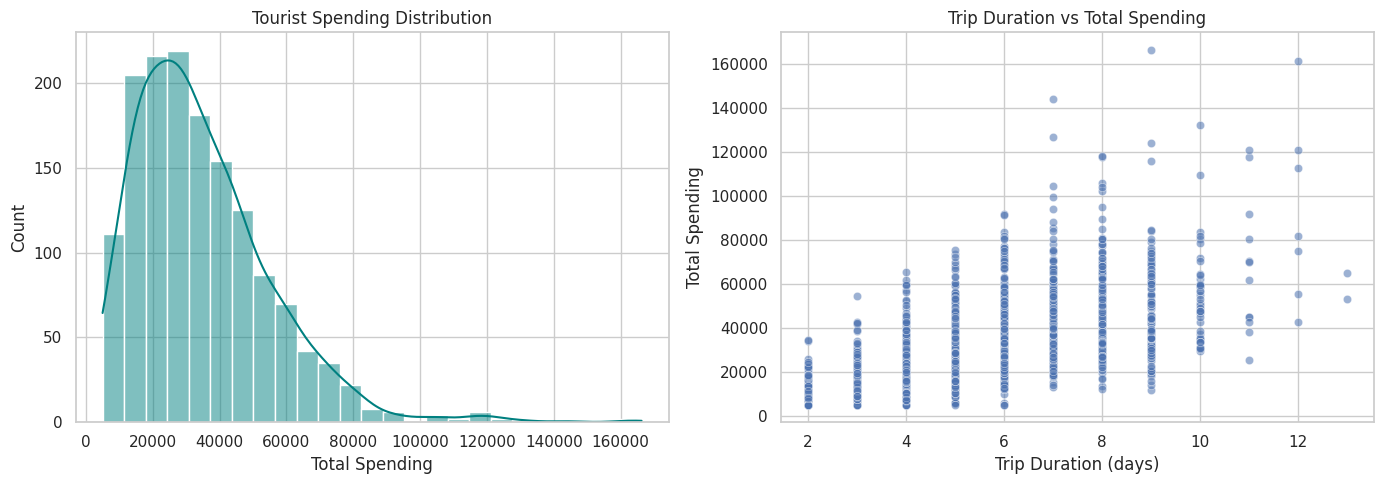

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["Total_Spending"], bins=25, kde=True, color="teal", ax=axes[0])
axes[0].set_title("Tourist Spending Distribution")
axes[0].set_xlabel("Total Spending")

sns.scatterplot(data=df, x="Trip_Duration", y="Total_Spending", alpha=0.55, ax=axes[1])
axes[1].set_title("Trip Duration vs Total Spending")
axes[1].set_xlabel("Trip Duration (days)")
axes[1].set_ylabel("Total Spending")

plt.tight_layout()
plt.show()

In [18]:
spending_by_type = (
    df.groupby("Travel_Type")["Total_Spending"]
      .agg(["count", "mean", "median", "max"])
      .sort_values("mean", ascending=False)
)
spending_by_type.round(2)

,count,mean,median,max
Travel_Type,,,,
Family,442,37658.21,33257.5,161388
Friends,312,34362.13,30759.5,126933
Couple,382,33768.25,29813.0,166285
Solo,364,32763.04,30154.0,120711


In [19]:
frequency_spending = (
    df.groupby("Travel_Frequency")["Total_Spending"]
      .mean()
      .sort_values(ascending=False)
      .reset_index()
)
frequency_spending.columns = ["Travel Frequency", "Average Spending"]
fig = px.bar(frequency_spending, x="Travel Frequency", y="Average Spending",
             title="Average Spending by Travel Frequency", text="Average Spending")
fig.update_traces(texttemplate="₹%{text:,.0f}", textposition="outside")
fig.show()

## 9. Satisfaction analysis

In [20]:
rating_count = df["Satisfaction_Rating"].value_counts().sort_index().reset_index()
rating_count.columns = ["Rating", "Tourists"]
fig = px.bar(rating_count, x="Rating", y="Tourists",
             title="Tourist Satisfaction Rating Distribution", text="Tourists")
fig.update_traces(textposition="outside")
fig.show()

In [21]:
satisfaction_by_destination = (
    df.groupby("Destination")["Satisfaction_Rating"]
      .mean()
      .sort_values(ascending=False)
      .reset_index()
)
satisfaction_by_destination.columns = ["Destination", "Average Satisfaction"]
fig = px.bar(satisfaction_by_destination, x="Average Satisfaction", y="Destination",
             orientation="h", title="Average Satisfaction by Destination")
fig.update_layout(yaxis=dict(categoryorder="total ascending"))
fig.show()

## 10. Correlation analysis

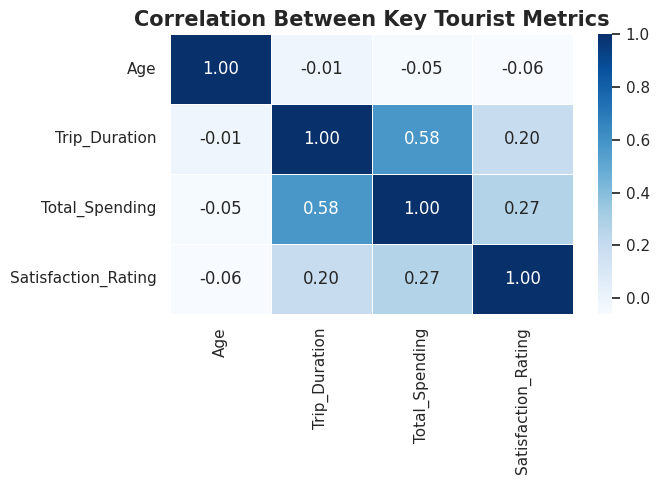

In [22]:
numeric_columns = ["Age", "Trip_Duration", "Total_Spending", "Satisfaction_Rating"]
correlation = df[numeric_columns].corr().round(2)

plt.figure(figsize=(7, 5))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="Blues", linewidths=0.5)
plt.title("Correlation Between Key Tourist Metrics", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

## 11. Behaviour cross-analysis

In [23]:
travel_transport = pd.crosstab(df["Travel_Type"], df["Transportation"])
travel_transport

Transportation,Bus,Car,Flight,Train
Travel_Type,,,,
Couple,94,83,91,114
Family,97,110,115,120
Friends,67,80,81,84
Solo,79,79,95,111


In [24]:
fig = px.imshow(travel_transport, text_auto=True, aspect="auto",
                title="Travel Type vs Transportation")
fig.show()

## 12. Tourist segmentation using K-Means clustering

Here we create simple behavioural segments using **Age, Trip Duration, Spending and Satisfaction**. Standardization is used because the variables have different scales.

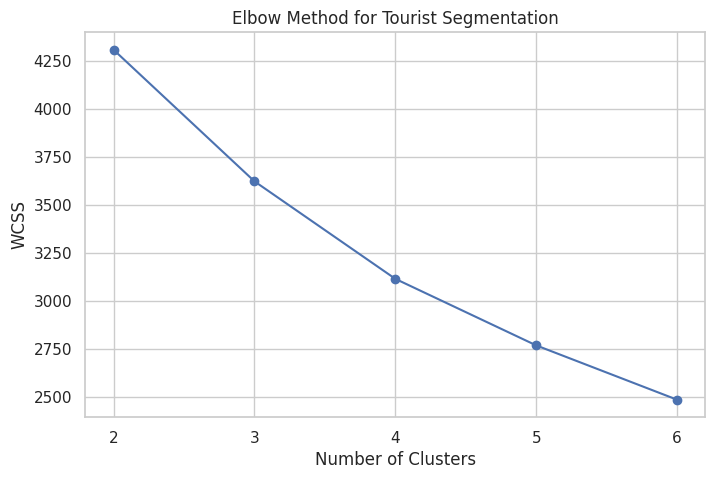

In [25]:
segment_data = df[["Age", "Trip_Duration", "Total_Spending", "Satisfaction_Rating"]].copy()
scaler = StandardScaler()
segment_scaled = scaler.fit_transform(segment_data)

# Elbow check for a small range of clusters
wcss = []
for k in range(2, 7):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(segment_scaled)
    wcss.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 7), wcss, marker="o")
plt.title("Elbow Method for Tourist Segmentation")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.xticks(range(2, 7))
plt.show()

In [26]:
# Four clusters give a simple and presentation-friendly segmentation
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df["Tourist_Segment"] = kmeans.fit_predict(segment_scaled) + 1

segment_profile = (
    df.groupby("Tourist_Segment")[
        ["Age", "Trip_Duration", "Total_Spending", "Satisfaction_Rating"]
    ].mean()
    .round(2)
)
segment_counts = df["Tourist_Segment"].value_counts().sort_index()
segment_profile["Tourist_Count"] = segment_counts
segment_profile

,Age,Trip_Duration,Total_Spending,Satisfaction_Rating,Tourist_Count
Tourist_Segment,,,,,
1,29.99,5.06,27093.69,4.13,390
2,33.62,8.06,58742.30,3.94,388
3,30.04,4.77,24526.48,2.91,410
4,48.56,5.25,28130.52,3.38,312


In [27]:
fig = px.scatter(df, x="Trip_Duration", y="Total_Spending",
                 color=df["Tourist_Segment"].astype(str),
                 size="Satisfaction_Rating",
                 hover_data=["Age", "Travel_Type", "Destination"],
                 title="Tourist Behaviour Segments")
fig.update_layout(coloraxis_colorbar_title="Segment")
fig.show()

## 13. Machine learning: Predict satisfaction category

For a simple supervised-learning demonstration, the satisfaction rating is converted into three meaningful categories:
- **Low:** 1–2
- **Medium:** 3
- **High:** 4–5

A Random Forest classifier is trained using tourist demographics and trip characteristics.

In [28]:
ml_df = df.copy()
ml_df["Satisfaction_Category"] = pd.cut(
    ml_df["Satisfaction_Rating"],
    bins=[0, 2, 3, 5],
    labels=["Low", "Medium", "High"]
)

features = [
    "Age", "Gender", "Country", "Travel_Frequency", "Travel_Type",
    "Destination", "Trip_Duration", "Accommodation_Type",
    "Transportation", "Activities", "Total_Spending"
]

X = ml_df[features]
y = ml_df["Satisfaction_Category"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

numeric_features = ["Age", "Trip_Duration", "Total_Spending"]
categorical_features = [column for column in features if column not in numeric_features]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(n_estimators=200, random_state=42))
])

model.fit(X_train, y_train)
predictions = model.predict(X_test)

accuracy = accuracy_score(y_test, predictions)
print(f"Random Forest Accuracy: {accuracy:.2%}")
print("\nClassification Report:")
print(classification_report(y_test, predictions))

Random Forest Accuracy: 56.67%

Classification Report:
              precision    recall  f1-score   support

        High       0.60      0.74      0.66       165
         Low       0.00      0.00      0.00         9
      Medium       0.49      0.38      0.43       126

    accuracy                           0.57       300
   macro avg       0.36      0.37      0.36       300
weighted avg       0.54      0.57      0.55       300



/opt/pyvenv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/opt/pyvenv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/opt/pyvenv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.



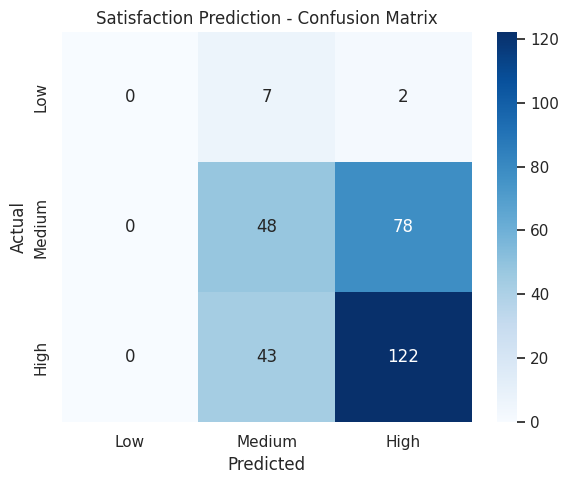

In [29]:
cm = confusion_matrix(y_test, predictions, labels=["Low", "Medium", "High"])

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Low", "Medium", "High"],
            yticklabels=["Low", "Medium", "High"])
plt.title("Satisfaction Prediction - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

## 14. Final tourist insights

The following cell generates a few project-ready findings directly from the dataset instead of manually typing numbers.

In [30]:
top_destination = df["Destination"].value_counts().idxmax()
best_satisfaction_destination = df.groupby("Destination")["Satisfaction_Rating"].mean().idxmax()
highest_spending_type = df.groupby("Travel_Type")["Total_Spending"].mean().idxmax()
most_used_transport = df["Transportation"].value_counts().idxmax()
avg_spending = df["Total_Spending"].mean()
avg_satisfaction = df["Satisfaction_Rating"].mean()
avg_trip = df["Trip_Duration"].mean()

print("TOURIST BEHAVIOUR & TRAVEL ANALYTICS - KEY INSIGHTS")
print("-" * 55)
print(f"Most visited destination: {top_destination}")
print(f"Highest average satisfaction destination: {best_satisfaction_destination}")
print(f"Highest average spending travel type: {highest_spending_type}")
print(f"Most used transportation: {most_used_transport}")
print(f"Average tourist spending: ₹{avg_spending:,.2f}")
print(f"Average satisfaction rating: {avg_satisfaction:.2f} / 5")
print(f"Average trip duration: {avg_trip:.2f} days")

TOURIST BEHAVIOUR & TRAVEL ANALYTICS - KEY INSIGHTS
-------------------------------------------------------
Most visited destination: Rajasthan
Highest average satisfaction destination: Kerala
Highest average spending travel type: Family
Most used transportation: Train
Average tourist spending: ₹34,794.09
Average satisfaction rating: 3.59 / 5
Average trip duration: 5.80 days


## 15. Conclusion

This project shows how Python can be used to understand tourist behaviour from raw data. The analysis covers **who travels, how often they travel, where they go, how they travel, what activities they prefer, how much they spend and how satisfied they are**.

The machine-learning sections add two data-science techniques: **K-Means clustering for tourist segmentation** and **Random Forest classification for satisfaction-category prediction**. These models are demonstrations of how analytics can support tourism decisions such as customer segmentation, destination planning, marketing and service improvement.

---
*Prepared by Gokul Prasad .M (RA2431022020007), B.Sc. AI & ML, SRM Institute of Science and Technology, Ramapuram, as part of a Python for Data Science project with Inspire Softech Solutions.*